In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

In [3]:
df = pd.read_csv("smartcart_customers.csv")

In [4]:
df["Income"] = df["Income"].fillna(df["Income"].median())

# Feature Engineering

In [5]:
# year
df["Age"] = 2026 - df["Year_Birth"]

In [6]:
# Dt_customer --> joining date
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst = True)

refrence_date = df["Dt_Customer"].max()

df["customer_Tenure_day"] = (refrence_date - df["Dt_Customer"]).dt.days

In [7]:
# columns add
df["Total_spending"] = (df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] 
                        + df["MntSweetProducts"] + df["MntGoldProds"])

In [8]:
# columns add
df["Childrens"] = df["Kidhome"] + df["Teenhome"]

In [9]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_Tenure_day,Total_spending,Childrens
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [10]:
# replace
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [11]:
df["Education"] = df["Education"].replace({
    "Basic":"UnderGraduate", "2n Cycle":"UnderGraduate",
    "Graduation":"Graduate",
    "PhD":"PostGraduate", "Master":"PostGraduate"
})

In [12]:
df["Living_style"] = df["Marital_Status"].replace({
    "Single":"Alone","Divorced":"Alone","Widow":"Alone","Alone":"Alone","Absurd":"Alone","YOLO":"Alone",
    "Married":"Partner", "Together":"Partner",
})

# Drop

In [13]:
col = ["ID","Year_Birth","Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
shop = ["MntWines","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

col_to_drop = col + shop

df = df.drop(columns = col_to_drop)

In [14]:
df.columns

Index(['Education', 'Income', 'Recency', 'MntFruits', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'customer_Tenure_day', 'Total_spending', 'Childrens', 'Living_style'],
      dtype='object')

In [15]:
df.shape

(2240, 16)

# Outliers

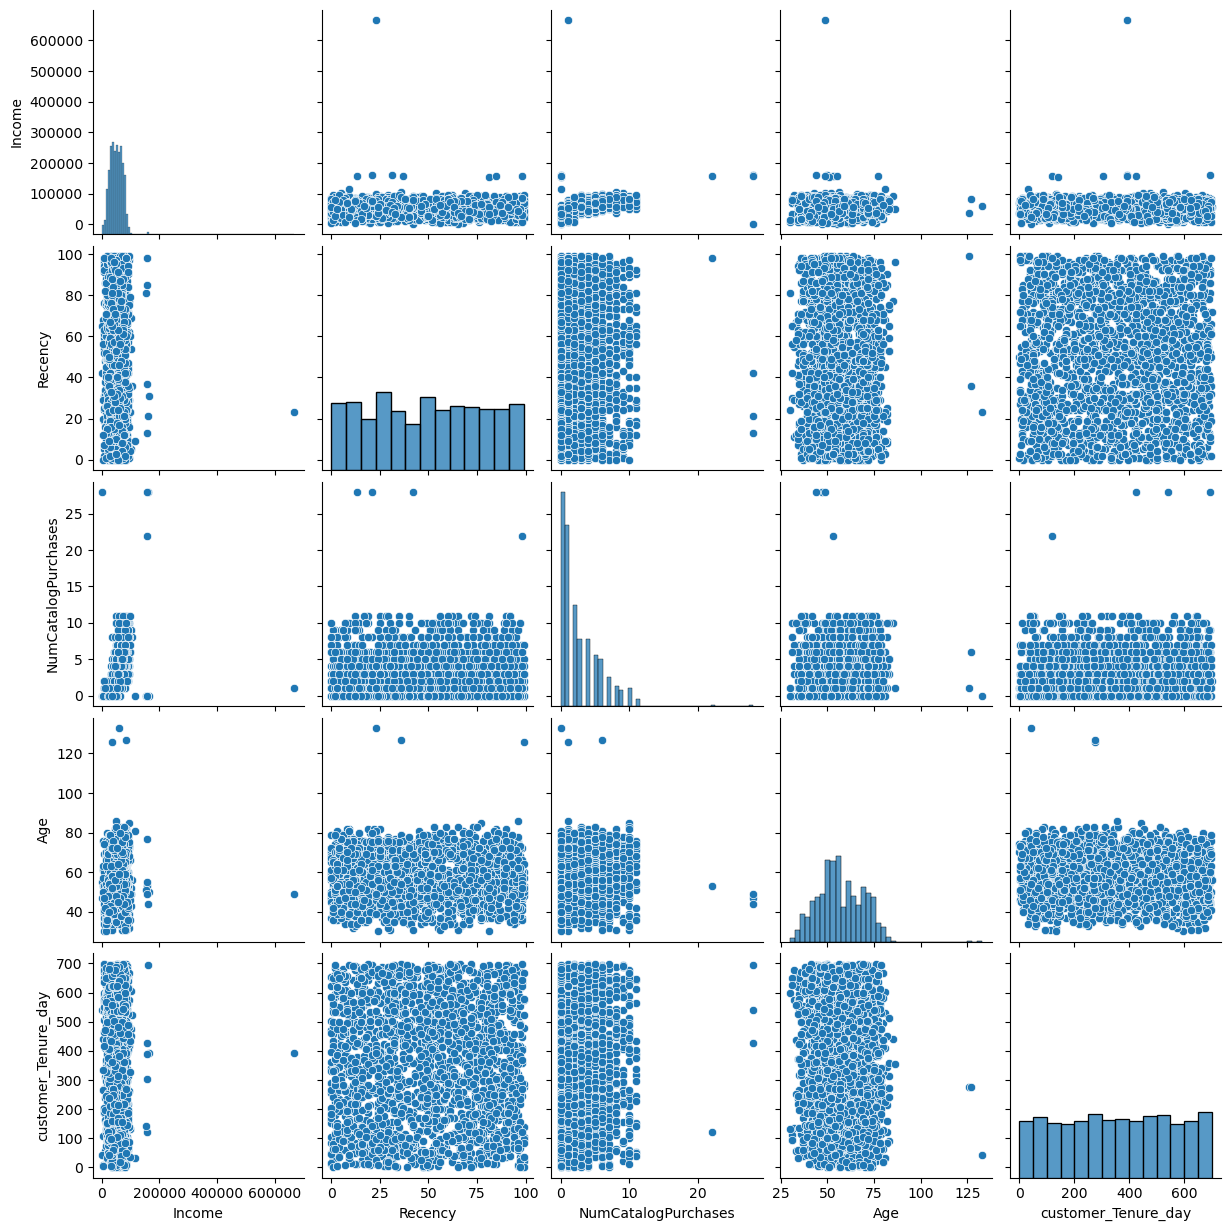

In [16]:
colu = ["Income", "Recency", "NumCatalogPurchases", "Age", "customer_Tenure_day"]

sns.pairplot(df[colu])

In [17]:
# remove outliers
print("data with outlier", len(df))

df = df[(df["Age"] < 90)]
df = df[(df["Income"] < 600_000)]

print("data without outlier", len(df))

data with outlier 2240
data without outlier 2236


In [18]:
df_cleaned = df

# HeatMap

In [19]:
Corr = df_cleaned.corr(numeric_only = True)

<Axes: >

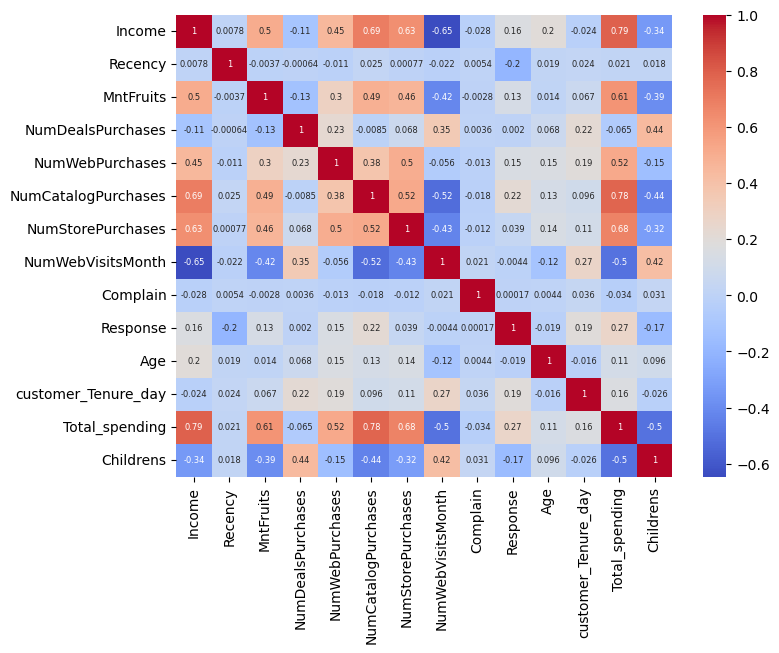

In [20]:
plt.figure(figsize = (8,6))
sns.heatmap(
    Corr,
    annot = True,
    annot_kws = {"size": 6},
    cmap = "coolwarm"
)

# OneHotEncoder

In [21]:
from sklearn.preprocessing import OneHotEncoder

In [22]:
one = OneHotEncoder()
col = ["Education","Living_style"]
enc_col = one.fit_transform(df_cleaned[col])

In [23]:
enc_df = pd.DataFrame(enc_col.toarray(), columns = one.get_feature_names_out(col), index = df_cleaned.index)

In [24]:
X = pd.concat([df_cleaned.drop(columns = col), enc_df], axis =1)

# Scaling

In [25]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Visualize

In [26]:
from sklearn.decomposition import PCA

In [27]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)

<Axes: >

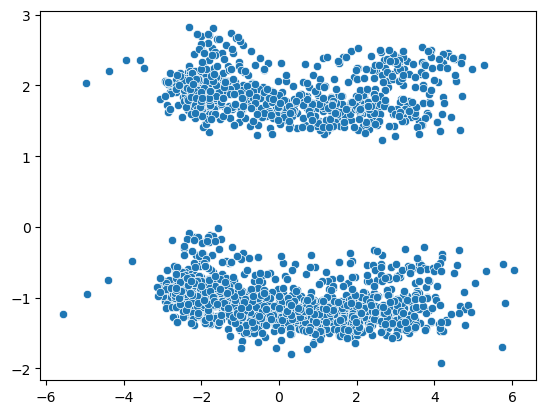

In [28]:
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1])

In [29]:
print(pca.explained_variance_ratio_)

[0.24149181 0.10787339]


In [30]:
# 3d
pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

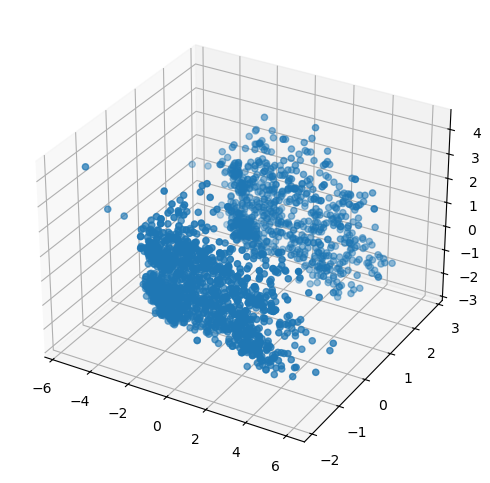

In [31]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2])

In [32]:
print(pca.explained_variance_ratio_)

[0.24149181 0.10787339 0.1003017 ]


# K- value find

## 1.Elbow Method

In [33]:
from sklearn.cluster import KMeans
wcss = []

for k in range(1,11):
    kmeans = KMeans(n_clusters = k)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

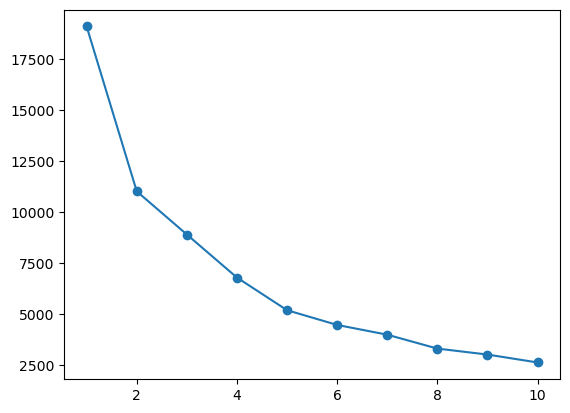

In [34]:
plt.plot(range(1,11), wcss, marker="o")

In [35]:
!pip install kneed

In [36]:
from kneed import KneeLocator

In [37]:
knee = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")
print("Optimal K :", knee.elbow)

Optimal K : 4


# Silhout_score

In [38]:
from sklearn.metrics import silhouette_score

In [39]:
ss = []

for k in range(2,11):
    kmeans = KMeans(n_clusters = k)
    labels = kmeans.fit_predict(X_pca)
    scores = silhouette_score(X_pca, labels)
    ss.append(scores)

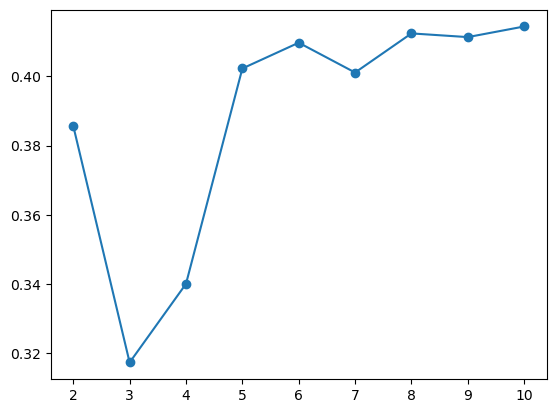

In [40]:
plt.plot(range(2,11), ss, marker="o")

Text(0, 0.5, 'ss')

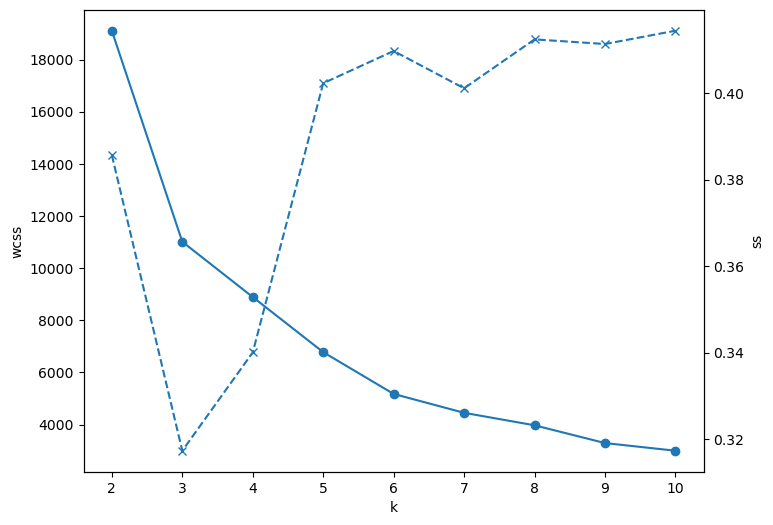

In [41]:
k = range(2,11)
fig, ax1 = plt.subplots(figsize = (8,6))

ax1.plot(k, wcss[:len(k)], marker = "o")
ax1.set_xlabel("k")
ax1.set_ylabel("wcss")

ax2 = ax1.twinx()
ax2.plot(k, ss[:len(k)], marker="x", linestyle ="--")
ax2.set_ylabel("ss")

In [42]:
# KMeans
kmeans = KMeans(n_clusters = 4)
labels = kmeans.fit_predict(X_pca)

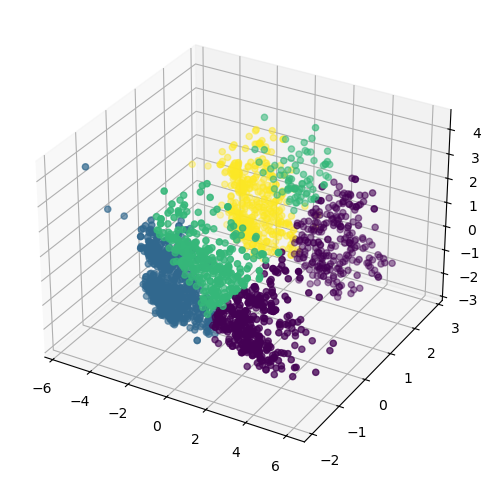

In [43]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c = labels)

# Agglomerative

In [44]:
from sklearn.cluster import AgglomerativeClustering

In [45]:
model = AgglomerativeClustering(n_clusters = 4, linkage = "ward")
labels = model.fit_predict(X_pca)

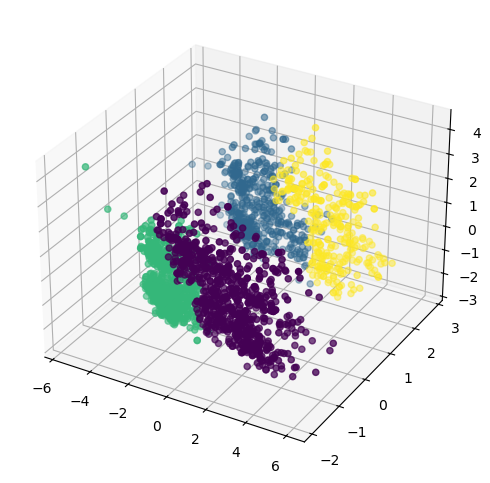

In [46]:
fig = plt.figure(figsize = (8,6))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c = labels)

# Charecteristic

In [52]:
X["cluster"] = labels

In [61]:
X.head()

,Education,Income,Recency,MntFruits,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_Tenure_day,Total_spending,Childrens,Living_style
0,Graduate,58138.0,58,88,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,1,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,49,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,4,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,43,5,5,3,6,5,0,0,45,161,422,1,Partner


<Axes: xlabel='cluster', ylabel='count'>

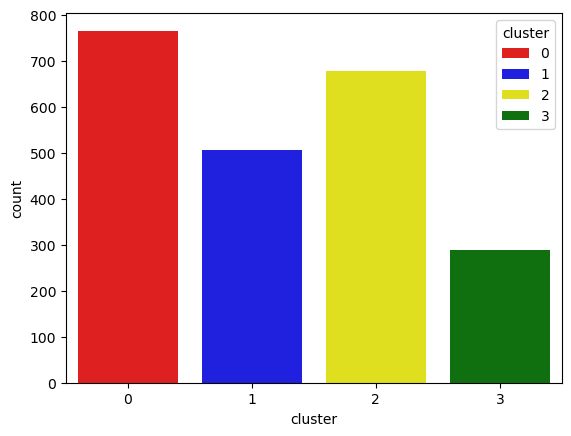

In [58]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x=df_cleaned["cluster"], palette = pal, hue = df_cleaned["cluster"])

<Axes: xlabel='Total_spending', ylabel='Income'>

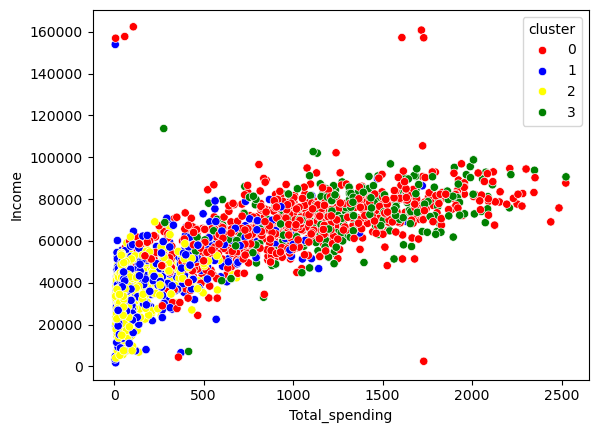

In [55]:
sns.scatterplot(x = X["Total_spending"],y = X["Income"], palette =pal, hue=X["cluster"] )

In [56]:
print(X.groupby("cluster").mean())

               Income    Recency  MntFruits  NumDealsPurchases  \
cluster                                                          
0        67167.792810  48.884967  43.250980           2.535948   
1        40743.733663  48.138614   8.877228           2.544554   
2        34599.378877  49.214180   5.454948           2.171344   
3        71914.596886  51.207612  60.519031           1.750865   

         NumWebPurchases  NumCatalogPurchases  NumStorePurchases  \
cluster                                                            
0               5.653595             4.499346           7.968627   
1               3.148515             1.160396           4.099010   
2               2.314623             0.548006           3.366322   
3               5.737024             5.384083           8.698962   

         NumWebVisitsMonth  Complain  Response        Age  \
cluster                                                     
0                 4.194771  0.006536  0.145098  59.690196   
1          